1. Import basic libraries. 


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

2. Load the dataset and print first 5 rows.


In [3]:
df = pd.read_excel('data/flight_price.xlsx')
df.head(5)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


3. Get the basic info. About the data.


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


4. Generate descriptive statistics of numeric columns. 


In [5]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


5. Detect and Handle Missing Value . 


In [6]:
df.isnull().sum()

mode_value = df[df['Total_Stops'].notna()]['Total_Stops'].mode()[0]
df['Total_Stops'] = df['Total_Stops'].fillna(mode_value)


In [7]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

6. Drop useless columns. 


In [8]:
df.drop('Route',axis=1,inplace=True)

In [9]:
df.drop('Additional_Info',axis=1,inplace=True)


In [10]:
df.drop('Duration',axis=1,inplace=True)

7. Remove outliers from numeric columns..

<Axes: ylabel='Price'>

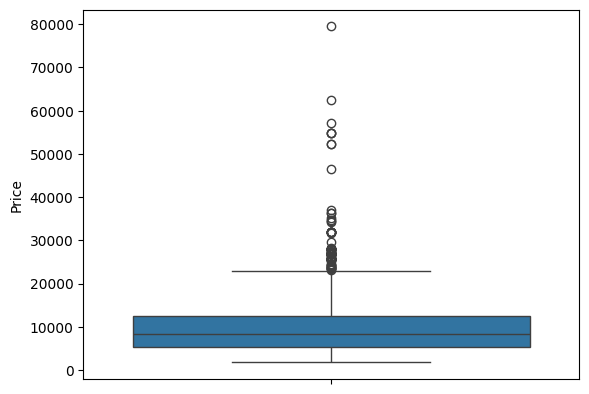

In [11]:
sns.boxplot(df['Price'])

In [12]:
# Only Numeric columns me outliers hote hai.....

# IQR method
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1

# Filter the data: outliers remove
df = df[~((df['Price'] < (Q1 - 1.5 * IQR)) | (df['Price'] > (Q3 + 1.5 * IQR)))]

In [13]:
df['Price'].value_counts()

Price
10262    258
10844    212
7229     162
4804     160
4823     131
        ... 
6273       1
14897      1
13432      1
8765       1
22294      1
Name: count, Length: 1826, dtype: int64

9. Given a column in format DD/MM/YYYY:
- Convert it into datetime
- Create new columns:
- Journey_Day
- Journey_Month
- journey_year
- Drop original column. 

In [14]:
# Only one time run otherwise second time show error
df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'], format='%d/%m/%Y')
df['Date'] = df['Date_of_Journey'].dt.day
df['Month'] = df['Date_of_Journey'].dt.month
df['year'] = df['Date_of_Journey'].dt.year


df.drop('Date_of_Journey', axis=1, inplace=True)


10. Given column of Time:
- Extract:
   - Dep_Hour
   - Dep_Min
- Drop original column

In [15]:
# Only one time run otherwise second time show error

df['Dep_Hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute

df.drop('Dep_Time',axis=1,inplace=True)

C:\Users\shali\AppData\Local\Temp\ipykernel_19872\2146315842.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dep_Hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
C:\Users\shali\AppData\Local\Temp\ipykernel_19872\2146315842.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute


In [16]:
# For Arrival_time
df['Arival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arival_minute'] = pd.to_datetime(df['Arrival_Time']).dt.minute

df.drop('Arrival_Time',axis=1,inplace=True)

C:\Users\shali\AppData\Local\Temp\ipykernel_19872\1894360133.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Arival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
C:\Users\shali\AppData\Local\Temp\ipykernel_19872\1894360133.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Arival_minute'] = pd.to_datetime(df['Arrival_Time']).dt.minute


11. Convert total_Stops into numeric 

In [17]:
df['Total_Stops'].unique()

array(['non-stop', '2 stops', '1 stop', '3 stops', '4 stops'],
      dtype=object)

In [18]:
# Only one time run otherwise show error in second time
df['Total_Stops'] = df['Total_Stops'].map({'non-stop':0,'1 stop':1,'2 stops':2,'3 stops':3,'4 stops':4})

12. Convert All Categoorical Data into numerical Data. 

In [19]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder()

encoded = encoder.fit_transform(df[['Airline','Source','Destination']]).toarray()

encoder_df = pd.DataFrame(encoded,columns=encoder.get_feature_names_out())
encoder_df.head()



,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,...,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [20]:
# combine data
drop_Df = df.drop(['Airline','Source','Destination'],axis=1)

In [21]:
# combine both dataset 
df = pd.concat([encoder_df.reset_index(drop=True),drop_Df.reset_index(drop=True)],axis=1)

##### Detect and remove outliers

13. Handle imbalence data by filling itself

In [22]:
df["Total_Stops"] = df["Total_Stops"].replace({3:2, 4:2})
df['Total_Stops'].value_counts()

Total_Stops
1    5551
0    3488
2    1550
Name: count, dtype: int64

In [23]:
df.columns

Index(['Airline_Air Asia', 'Airline_Air India', 'Airline_GoAir',
       'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata',
       'Source_Mumbai', 'Destination_Banglore', 'Destination_Cochin',
       'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata',
       'Destination_New Delhi', 'Total_Stops', 'Price', 'Date', 'Month',
       'year', 'Dep_Hour', 'Dep_min', 'Arival_hour', 'Arival_minute'],
      dtype='object')

In [25]:
df.to_csv('data/cleand_data/clean_flight.csv',index=False)

**Conclusion :** Now the dataset is fully Clean this time ready for training purpose.